<a href="https://colab.research.google.com/github/JavilmIB/Activities/blob/main/Assignments/CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 5.- Convolutional Neural Network

**Class:** Artificial Intelligence  
**Professor:** Daniel Isaías López Páez  
**Group:** 001  
**Class time:** Tuesday N4

| Name | Student ID |
|---|---|
| Alejandra Montserrat Hernández Uribe | 1898320 |
| Javier Ivan Lomas Maldonado | 2096554 |
| Adrian Caballero Mena | 2056248 |


## 1. Load libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers
from keras.datasets import mnist
from keras.utils import to_categorical

keras.utils.set_random_seed(42)   # reproducible results
print("Keras version:", keras.__version__)

Keras version: 3.13.2


## 2. Load data
The MNIST dataset is part of the Keras library. It contains 70,000 grayscale images of 28×28 pixels with handwritten digits from 0 to 9. The `load_data()` function returns the default split: 60,000 images for training and 10,000 for testing.

In [2]:
(train_data, train_labels), (test_data, test_label) = mnist.load_data()

print("train_data:  ", train_data.shape, "| train_labels:", train_labels.shape)
print("test_data:   ", test_data.shape, "| test_label:  ", test_label.shape)
print("Pixel values from", train_data.min(), "to", train_data.max())
print("Digits per class (training):", np.bincount(train_labels))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
train_data:   (60000, 28, 28) | train_labels: (60000,)
test_data:    (10000, 28, 28) | test_label:   (10000,)
Pixel values from 0 to 255
Digits per class (training): [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


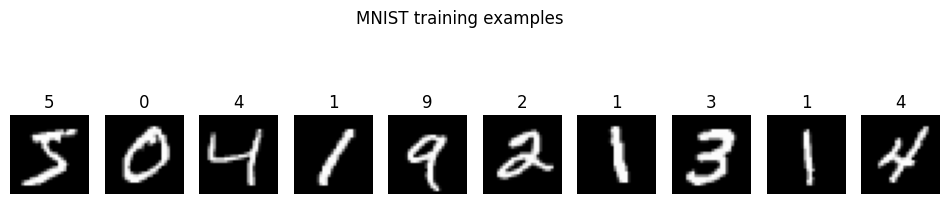

In [3]:
# First 10 images of the training set
plt.figure(figsize=(12, 3))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(train_data[i], cmap="gray")
    plt.title(train_labels[i])
    plt.axis("off")
plt.suptitle("MNIST training examples")
plt.show()

## 3. Data preprocessing
- **Reshape:** a convolutional layer expects images with a channel dimension, so each image goes from (28, 28) to (28, 28, 1) (1 channel = grayscale).
- **Normalization:** pixel values are divided by 255 to go from 0–255 to 0–1, which makes training faster and more stable.
- **One-hot encoding:** the labels are converted to vectors of 10 positions with `to_categorical` (e.g. 3 → [0,0,0,1,0,0,0,0,0,0]) to match the 10 outputs of the softmax layer.

In [4]:
train_data_cnn = train_data.reshape(-1, 28, 28, 1).astype("float32") / 255
test_data_cnn = test_data.reshape(-1, 28, 28, 1).astype("float32") / 255

train_labels_cat = to_categorical(train_labels, 10)
test_label_cat = to_categorical(test_label, 10)

print("train_data_cnn:", train_data_cnn.shape, "| range:", train_data_cnn.min(), "-", train_data_cnn.max())
print("test_data_cnn: ", test_data_cnn.shape)
print("Label", train_labels[0], "->", train_labels_cat[0])

train_data_cnn: (60000, 28, 28, 1) | range: 0.0 - 1.0
test_data_cnn:  (10000, 28, 28, 1)
Label 5 -> [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


## 4. Model selection and training
Proposed structure of the convolutional neural network:

| Layer | Configuration | Purpose |
|---|---|---|
| Conv2D | 32 filters 3×3, ReLU | Detects simple features (edges, strokes) |
| MaxPooling2D | 2×2 | Reduces the size of the feature maps |
| Conv2D | 64 filters 3×3, ReLU | Detects more complex shapes (curves, loops) |
| MaxPooling2D | 2×2 | Reduces size again |
| Flatten | — | Converts the maps into a vector |
| Dropout | 0.5 | Reduces overfitting |
| Dense (output) | 10 neurons, **softmax** | Probability of each digit 0–9 |

- **Loss function:** `categorical_crossentropy` (multi-class classification with one-hot labels).
- **Optimizer:** `adam`.
- **Metric:** `accuracy`.

In [5]:
model = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax"),
])

model.compile(loss="categorical_crossentropy",
              optimizer="adam",
              metrics=["accuracy"])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        16,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,826 (136.04 KB)

 Trainable params: 34,826 (136.04 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
history = model.fit(train_data_cnn, train_labels_cat,
                    batch_size=128,
                    epochs=10,
                    validation_split=0.1,
                    verbose=2)

Epoch 1/10
422/422 - 39s - 92ms/step - accuracy: 0.8924 - loss: 0.3586 - val_accuracy: 0.9780 - val_loss: 0.0805
Epoch 2/10
422/422 - 38s - 89ms/step - accuracy: 0.9662 - loss: 0.1096 - val_accuracy: 0.9835 - val_loss: 0.0579
Epoch 3/10
422/422 - 37s - 87ms/step - accuracy: 0.9740 - loss: 0.0848 - val_accuracy: 0.9877 - val_loss: 0.0460
Epoch 4/10
422/422 - 35s - 84ms/step - accuracy: 0.9782 - loss: 0.0703 - val_accuracy: 0.9878 - val_loss: 0.0427
Epoch 5/10
422/422 - 37s - 87ms/step - accuracy: 0.9806 - loss: 0.0632 - val_accuracy: 0.9888 - val_loss: 0.0384
Epoch 6/10
422/422 - 37s - 87ms/step - accuracy: 0.9823 - loss: 0.0563 - val_accuracy: 0.9895 - val_loss: 0.0368
Epoch 7/10
422/422 - 41s - 97ms/step - accuracy: 0.9844 - loss: 0.0513 - val_accuracy: 0.9908 - val_loss: 0.0336
Epoch 8/10
422/422 - 36s - 85ms/step - accuracy: 0.9844 - loss: 0.0495 - val_accuracy: 0.9912 - val_loss: 0.0326
Epoch 9/10
422/422 - 43s - 102ms/step - accuracy: 0.9851 - loss: 0.0460 - val_accuracy: 0.9905 -

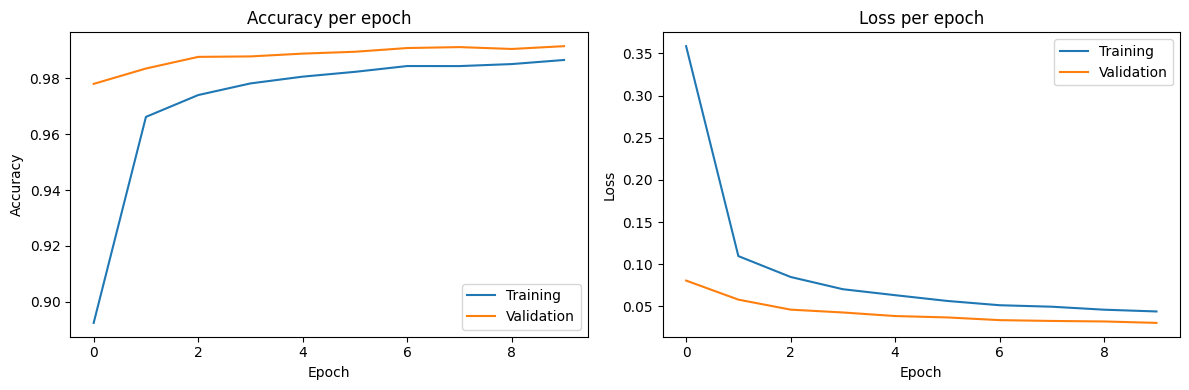

In [7]:
# Training curves
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy per epoch"); plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss per epoch"); plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend()
plt.tight_layout()
plt.savefig("training_curves.png", dpi=150)
plt.show()

## 5. Model testing
### Accuracy with the test dataset (`evaluate`)

In [8]:
test_loss, test_accuracy = model.evaluate(test_data_cnn, test_label_cat, verbose=0)
print(f"Test loss:     {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")

Test loss:     0.0305
Test accuracy: 0.9903 (99.03%)


### 5 different predictions with the test dataset

Image # 6249 -> Prediction: 9 | Actual value: 9 | Confidence: 99.92%
Image # 6840 -> Prediction: 3 | Actual value: 3 | Confidence: 99.30%
Image # 9445 -> Prediction: 3 | Actual value: 3 | Confidence: 100.00%
Image # 5782 -> Prediction: 4 | Actual value: 4 | Confidence: 100.00%
Image # 8971 -> Prediction: 1 | Actual value: 1 | Confidence: 99.99%


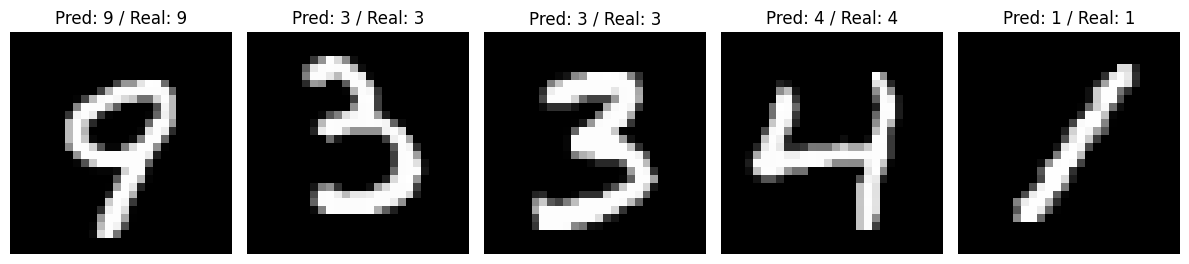

In [9]:
rng = np.random.default_rng(7)
indices = rng.choice(len(test_data), size=5, replace=False)

probabilities = model.predict(test_data_cnn[indices], verbose=0)
predictions = np.argmax(probabilities, axis=1)

plt.figure(figsize=(12, 3))
for i, idx in enumerate(indices):
    print(f"Image #{idx:5d} -> Prediction: {predictions[i]} | Actual value: {test_label[idx]} "
          f"| Confidence: {probabilities[i].max()*100:.2f}%")
    plt.subplot(1, 5, i + 1)
    plt.imshow(test_data[idx], cmap="gray")
    plt.title(f"Pred: {predictions[i]} / Real: {test_label[idx]}")
    plt.axis("off")
plt.tight_layout()
plt.savefig("predictions.png", dpi=150)
plt.show()